In [11]:

import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from google.colab import files
from pathlib import Path

# Make results more reproducible
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Python libraries loaded successfully!")
print("TensorFlow version:", tf.__version__)
print("Available GPU:", tf.config.list_physical_devices("GPU"))


Python libraries loaded successfully!
TensorFlow version: 2.21.0
Available GPU: []


In [2]:

uploaded = files.upload()

FILE_PATH = next(
    name for name in uploaded.keys()
    if name.lower().endswith(".txt")
)

raw_text = Path(FILE_PATH).read_text(
    encoding="utf-8-sig",
    errors="replace"
)

print("\nDataset loaded successfully!")
print("File name:", FILE_PATH)
print("Total characters:", len(raw_text))
print("\nFirst 500 characters:\n")
print(raw_text[:500])


Saving 1661-0.txt to 1661-0.txt

Dataset loaded successfully!
File name: 1661-0.txt
Total characters: 581887

First 500 characters:


Project Gutenberg's The Adventures of Sherlock Holmes, by Arthur Conan Doyle

This eBook is for the use of anyone anywhere at no cost and with
almost no restrictions whatsoever.  You may copy it, give it away or
re-use it under the terms of the Project Gutenberg License included
with this eBook or online at www.gutenberg.net


Title: The Adventures of Sherlock Holmes

Author: Arthur Conan Doyle

Release Date: November 29, 2002 [EBook #1661]
Last Updated: May 20, 2019

Language: English

Charact


In [3]:

# Step 2: Remove Project Gutenberg header and footer

start_pattern = (
    r"\*\*\*\s*START OF (?:THE|THIS) PROJECT GUTENBERG EBOOK"
    r"[^\n]*\*\*\*"
)

end_pattern = (
    r"\*\*\*\s*END OF (?:THE|THIS) PROJECT GUTENBERG EBOOK"
    r"[^\n]*\*\*\*"
)

start_match = re.search(
    start_pattern, raw_text, flags=re.IGNORECASE
)

if start_match:
    text_after_header = raw_text[start_match.end():]
else:
    raise ValueError("Start marker not found. Check the file format.")

end_match = re.search(
    end_pattern, text_after_header, flags=re.IGNORECASE
)

if end_match:
    clean_text = text_after_header[:end_match.start()]
else:
    raise ValueError("End marker not found. Check the file format.")

# Normalize whitespace
clean_text = re.sub(r"\s+", " ", clean_text).strip()

print("Dataset cleaning completed!")
print("Original characters:", len(raw_text))
print("Cleaned characters:", len(clean_text))
print("\nFirst 500 characters of cleaned text:\n")
print(clean_text[:500])


Dataset cleaning completed!
Original characters: 581887
Cleaned characters: 559380

First 500 characters of cleaned text:

Produced by an anonymous Project Gutenberg volunteer and Jose Menendez cover The Adventures of Sherlock Holmes by Arthur Conan Doyle Contents I. A Scandal in Bohemia II. The Red-Headed League III. A Case of Identity IV. The Boscombe Valley Mystery V. The Five Orange Pips VI. The Man with the Twisted Lip VII. The Adventure of the Blue Carbuncle VIII. The Adventure of the Speckled Band IX. The Adventure of the Engineer’s Thumb X. The Adventure of the Noble Bachelor XI. The Adventure of the Beryl C


In [4]:

# STEP 3: Tokenization and Vocabulary Inspection

# 1. Split the cleaned text into sentence-like units
sentence_strings = re.split(
    r"(?<=[.!?])\s+",
    clean_text
)

# 2. Convert text into lowercase word tokens
def tokenize_words(text):
    return re.findall(
        r"[a-z]+(?:'[a-z]+)?",
        text.lower()
    )

# 3. Tokenize each sentence and remove very short units
sentences = []

for sentence in sentence_strings:
    words = tokenize_words(sentence)

    if len(words) >= 3:
        sentences.append(words)

# 4. Collect all word tokens
all_words = [
    word
    for sentence in sentences
    for word in sentence
]

# 5. Find unique words
vocabulary = set(all_words)

# 6. Display dataset statistics
print("TOKENIZATION COMPLETED")
print("-" * 35)
print("Sentence-like units:", len(sentences))
print("Total word tokens:", len(all_words))
print("Unique word forms:", len(vocabulary))

print(
    "Average words per sentence:",
    round(len(all_words) / max(len(sentences), 1), 2)
)

# 7. Display the first five tokenized sentences
print("\nFIRST FIVE TOKENIZED SENTENCES")
print("-" * 35)

for i, sentence in enumerate(sentences[:5], start=1):
    print(f"{i}. {' '.join(sentence)}")

# 8. Display the 20 most frequent words
from collections import Counter

word_counts = Counter(all_words)

print("\n20 MOST FREQUENT WORDS")
print("-" * 35)

for word, count in word_counts.most_common(20):
    print(f"{word}: {count}")


TOKENIZATION COMPLETED
-----------------------------------
Sentence-like units: 4914
Total word tokens: 105569
Unique word forms: 7814
Average words per sentence: 21.48

FIRST FIVE TOKENIZED SENTENCES
-----------------------------------
1. produced by an anonymous project gutenberg volunteer and jose menendez cover the adventures of sherlock holmes by arthur conan doyle contents i
2. a scandal in bohemia ii
3. the red headed league iii
4. a case of identity iv
5. the boscombe valley mystery v

20 MOST FREQUENT WORDS
-----------------------------------
the: 5630
i: 3038
and: 3012
to: 2744
of: 2658
a: 2643
in: 1764
that: 1751
it: 1734
you: 1496
he: 1481
was: 1410
his: 1159
is: 1124
my: 1005
have: 924
as: 852
had: 831
with: 830
which: 771


In [5]:

# STEP 4A: Remove the front matter and table of contents

# Start at the first story heading.
story_marker = re.search(
    r"\bI\.\s*A Scandal in Bohemia\b",
    clean_text,
    flags=re.IGNORECASE
)

if story_marker:
    story_text = clean_text[story_marker.start():]
else:
    raise ValueError(
        "Story heading not found. Please inspect clean_text."
    )

print("Front matter removed.")
print("Story text characters:", len(story_text))
print("\nStory text preview:\n")
print(story_text[:500])


Front matter removed.
Story text characters: 559238

Story text preview:

I. A Scandal in Bohemia II. The Red-Headed League III. A Case of Identity IV. The Boscombe Valley Mystery V. The Five Orange Pips VI. The Man with the Twisted Lip VII. The Adventure of the Blue Carbuncle VIII. The Adventure of the Speckled Band IX. The Adventure of the Engineer’s Thumb X. The Adventure of the Noble Bachelor XI. The Adventure of the Beryl Coronet XII. The Adventure of the Copper Beeches I. A SCANDAL IN BOHEMIA I. To Sherlock Holmes she is always _the_ woman. I have seldom heard h


In [6]:

# STEP 4B: Rebuild sentences and vocabulary from story text

sentence_strings = re.split(
    r"(?<=[.!?])\s+",
    story_text
)

sentences = []

for sentence in sentence_strings:
    words = tokenize_words(sentence)

    if len(words) >= 3:
        sentences.append(words)

all_words = [
    word
    for sentence in sentences
    for word in sentence
]

vocabulary = set(all_words)

print("REFINED DATASET STATISTICS")
print("-" * 35)
print("Sentence-like units:", len(sentences))
print("Total word tokens:", len(all_words))
print("Unique word forms:", len(vocabulary))
print(
    "Average words per sentence:",
    round(len(all_words) / max(len(sentences), 1), 2)
)

print("\nFirst 3 sentences:\n")
for i, sentence in enumerate(sentences[:3], start=1):
    print(f"{i}. {' '.join(sentence)}")


REFINED DATASET STATISTICS
-----------------------------------
Sentence-like units: 4913
Total word tokens: 105547
Unique word forms: 7810
Average words per sentence: 21.48

First 3 sentences:

1. a scandal in bohemia ii
2. the red headed league iii
3. a case of identity iv


In [8]:

# 4C Find the actual beginning of the first story
actual_start = re.search(
    r"I\.\s*A SCANDAL IN BOHEMIA\s+I\.\s*To Sherlock Holmes",
    clean_text,
    flags=re.IGNORECASE
)

if actual_start:
    story_text = clean_text[actual_start.start():]
    print("Actual story beginning found!")
    print("\nStory preview:\n")
    print(story_text[:400])
else:
    print("Story beginning not found. We need to inspect the heading.")


Actual story beginning found!

Story preview:

I. A SCANDAL IN BOHEMIA I. To Sherlock Holmes she is always _the_ woman. I have seldom heard him mention her under any other name. In his eyes she eclipses and predominates the whole of her sex. It was not that he felt any emotion akin to love for Irene Adler. All emotions, and that one particularly, were abhorrent to his cold, precise but admirably balanced mind. He was, I take it, the most perfe


In [9]:

sentence_strings = re.split(r"(?<=[.!?])\s+", story_text)

sentences = []
for sentence in sentence_strings:
    words = tokenize_words(sentence)
    if len(words) >= 3:
        sentences.append(words)

all_words = [word for sentence in sentences for word in sentence]
vocabulary = set(all_words)

print("CORRECTED DATASET STATISTICS")
print("-" * 35)
print("Sentence-like units:", len(sentences))
print("Total word tokens:", len(all_words))
print("Unique word forms:", len(vocabulary))
print("Average words per sentence:",
      round(len(all_words) / max(len(sentences), 1), 2))

print("\nFirst 3 sentences:\n")
for i, sentence in enumerate(sentences[:3], start=1):
    print(f"{i}. {' '.join(sentence)}")


CORRECTED DATASET STATISTICS
-----------------------------------
Sentence-like units: 4901
Total word tokens: 105472
Unique word forms: 7808
Average words per sentence: 21.52

First 3 sentences:

1. a scandal in bohemia i
2. to sherlock holmes she is always the woman
3. i have seldom heard him mention her under any other name


In [10]:

from sklearn.model_selection import train_test_split
import random

# Set a fixed seed for reproducible results
SEED = 42
random.seed(SEED)

# Split 10% of the data for testing
train_val_sentences, test_sentences = train_test_split(
    sentences,
    test_size=0.10,
    random_state=SEED,
    shuffle=True
)

# Split the remaining 90% into training and validation
train_sentences, val_sentences = train_test_split(
    train_val_sentences,
    test_size=1/9,
    random_state=SEED,
    shuffle=True
)

# Display the results
print("DATASET SPLIT COMPLETED")
print("-" * 35)
print("Training sentences:", len(train_sentences))
print("Validation sentences:", len(val_sentences))
print("Testing sentences:", len(test_sentences))
print(
    "Total sentences:",
    len(train_sentences) + len(val_sentences) + len(test_sentences)
)


DATASET SPLIT COMPLETED
-----------------------------------
Training sentences: 3920
Validation sentences: 490
Testing sentences: 491
Total sentences: 4901


In [12]:

from tensorflow.keras.preprocessing.text import Tokenizer

# Initialize the tokenizer
tokenizer = Tokenizer(
    filters='!"#$%&()*+,-./:;<=>?@[\\]^_`{|}~\t\n',
    lower=True,
    oov_token="<OOV>"
)

# Train the tokenizer using training sentences only
tokenizer.fit_on_texts(
    [" ".join(sentence) for sentence in train_sentences]
)

# Create the word-to-number mapping
word_index = tokenizer.word_index
vocab_size = len(word_index) + 1

print("TOKENIZATION COMPLETED")
print("-" * 35)
print("Vocabulary size:", vocab_size)
print("\nExample word indexes:")

for word in ["the", "sherlock", "holmes", "woman"]:
    print(f"{word}: {word_index.get(word, 'Not found')}")


TOKENIZATION COMPLETED
-----------------------------------
Vocabulary size: 7144

Example word indexes:
the: 2
sherlock: 133
holmes: 34
woman: 164


In [13]:

input_sequences = []

for sentence in train_sentences:
    text = " ".join(sentence)
    token_list = tokenizer.texts_to_sequences([text])[0]

    # Create progressively longer sequences
    for i in range(2, len(token_list) + 1):
        input_sequences.append(token_list[:i])

print("SEQUENCES CREATED")
print("-" * 35)
print("Total training sequences:", len(input_sequences))
print("\nFirst 5 sequences:")

for seq in input_sequences[:5]:
    print(seq, "->", tokenizer.sequences_to_texts([seq]))


SEQUENCES CREATED
-----------------------------------
Total training sequences: 81276

First 5 sequences:
[4, 17] -> ['i have']
[4, 17, 39] -> ['i have no']
[4, 17, 39, 44] -> ['i have no one']
[4, 17, 39, 44, 5] -> ['i have no one to']
[4, 17, 39, 44, 5, 351] -> ['i have no one to turn']


In [14]:

from tensorflow.keras.preprocessing.sequence import pad_sequences
import numpy as np

# step 8 Find the longest sequence
max_sequence_len = max(len(seq) for seq in input_sequences)

# Make all sequences the same length
padded_sequences = pad_sequences(
    input_sequences,
    maxlen=max_sequence_len,
    padding="pre"
)

# X contains context words; y contains the target next word
X = padded_sequences[:, :-1]
y = padded_sequences[:, -1]

print("INPUT AND TARGET PREPARATION COMPLETED")
print("-" * 40)
print("Maximum sequence length:", max_sequence_len)
print("Input shape (X):", X.shape)
print("Target shape (y):", y.shape)
print("\nFirst input sequence:", X[0])
print("First target word ID:", y[0])
print("Target word:", tokenizer.sequences_to_texts([[int(y[0])]]))


INPUT AND TARGET PREPARATION COMPLETED
----------------------------------------
Maximum sequence length: 249
Input shape (X): (81276, 248)
Target shape (y): (81276,)

First input sequence: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 4]
First target word ID: 17
Target word: ['have']


In [16]:

#step 9 LSTM
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# Build the next-word prediction model
model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=100,
        mask_zero=True
    ),
    LSTM(128),
    Dropout(0.2),
    Dense(vocab_size, activation="softmax")
])

# Configure the model for training
model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=Adam(learning_rate=0.001),
    metrics=["accuracy"]
)

# Display model architecture
model.build(input_shape=(None, X.shape[1]))
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 248, 100)       │       714,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │       117,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7144)           │       921,576 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,753,224 (6.69 MB)

 Trainable params: 1,753,224 (6.69 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:

from tensorflow.keras.callbacks import EarlyStopping

# Stop training if validation loss stops improving
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

# Train the LSTM model
history = model.fit(
    X,
    y,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stopping],
    verbose=1
)

print("\nMODEL TRAINING COMPLETED")


Epoch 1/10
1143/1143 ━━━━━━━━━━━━━━━━━━━━ 670s 585ms/step - accuracy: 0.0618 - loss: 6.5172 - val_accuracy: 0.0827 - val_loss: 6.2197
Epoch 2/10
1143/1143 ━━━━━━━━━━━━━━━━━━━━ 674s 590ms/step - accuracy: 0.0958 - loss: 5.9041 - val_accuracy: 0.1075 - val_loss: 5.9518
Epoch 3/10
1143/1143 ━━━━━━━━━━━━━━━━━━━━ 670s 586ms/step - accuracy: 0.1143 - loss: 5.6000 - val_accuracy: 0.1179 - val_loss: 5.8656
Epoch 4/10
1143/1143 ━━━━━━━━━━━━━━━━━━━━ 693s 607ms/step - accuracy: 0.1271 - loss: 5.3853 - val_accuracy: 0.1246 - val_loss: 5.8403
Epoch 5/10
1143/1143 ━━━━━━━━━━━━━━━━━━━━ 694s 607ms/step - accuracy: 0.1381 - loss: 5.2032 - val_accuracy: 0.1310 - val_loss: 5.8410
Epoch 6/10
1143/1143 ━━━━━━━━━━━━━━━━━━━━ 675s 591ms/step - accuracy: 0.1492 - loss: 5.0344 - val_accuracy: 0.1344 - val_loss: 5.8580

MODEL TRAINING COMPLETED


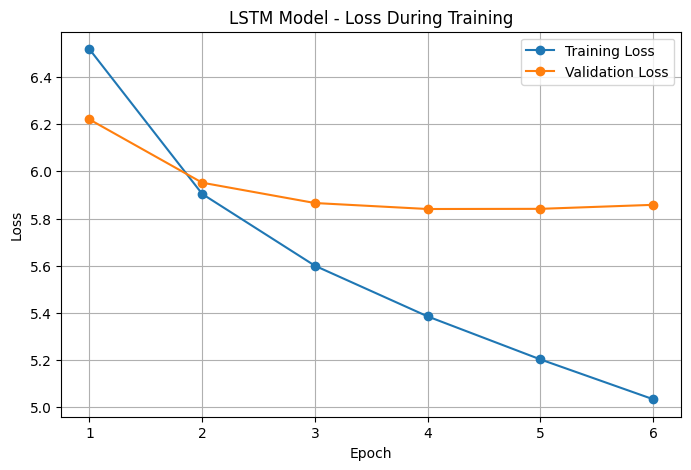

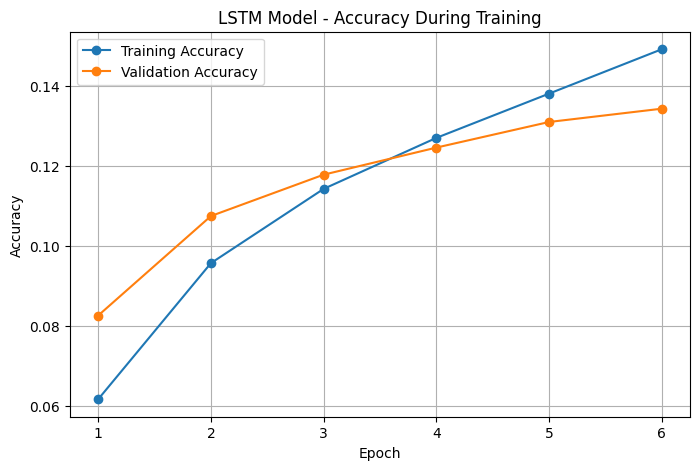

In [20]:

import matplotlib.pyplot as plt

# Get training history
epochs = range(1, len(history.history["loss"]) + 1)

# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(epochs, history.history["loss"], marker="o",
         label="Training Loss")
plt.plot(epochs, history.history["val_loss"], marker="o",
         label="Validation Loss")
plt.title("LSTM Model - Loss During Training")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

# Plot training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(epochs, history.history["accuracy"], marker="o",
         label="Training Accuracy")
plt.plot(epochs, history.history["val_accuracy"], marker="o",
         label="Validation Accuracy")
plt.title("LSTM Model - Accuracy During Training")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()
